## Exercise 3 - Hints and solutions

The **hints** come first. Try to solve each step with the help of the hints.

The **solutions** are at the bottom of this notebook. Look at them only after you have tried!

---
# Hints

## Part 1 - The samples

**1. Read a sheet**

```py
samples = pd.read_excel(file, sheet_name='...')
samples
```

The sheet names are `samples` and `DE_results`.

**2. New column**

Divide the column by one million and give the result a new column name:

```py
samples['new_column'] = samples['old_column'] / 1000000
```

**3. Bar plot**

```py
samples.plot(kind='bar', x='...', y='...', title='...', xlabel='...', ylabel='...')
```

The x axis is the sample name, the y axis is the number of million reads.

**4. The strange sample**

Look at your bar plot: which bar is much lower? Then look at `percent_mapped` for the same sample. A low mapping rate often means the RNA was degraded or the sample was contaminated.

**5. Mean per condition**

Use `groupby`, like in the lecture:

```py
df.groupby('column to group by')['column to calculate'].mean()
```

## Part 2 - The results

**6. Size and missing values**

- `.shape` gives `(rows, columns)`. One row is one gene.
- In the output of `.info()`, look at **Non-Null Count**. A column with fewer values than the number of rows has missing values.

**7. Look at one gene**

Select the rows where the column `gene` is equal to `'ALB'`:

```py
results[results['gene'] == 'ALB']
```

Then look at `baseMean`. Remember that these cells are not liver cells.

**8. VEGFA**

- Select the row of `VEGFA` the same way as for `ALB`.
- Is `log2FoldChange` positive (up) or negative (down)?
- Calculate `2 ** log2FoldChange` with the number you see, e.g. `2 ** 3.5`.

**9. Significant genes**

```py
significant = results[results['padj'] < 0.05]
```

Use `len()` or `.shape` to count the rows.

**10. Up and down**

Two conditions must be true at the same time, so use `&` and put each condition in brackets:

```py
up = results[(condition 1) & (condition 2)]
```

For the last question, look at the `log2FoldChange` of the significant genes that are neither in `up` nor in `down`: are they large or small changes?

**11. Top 10**

- Sort `up` with `.sort_values('log2FoldChange', ascending=False)`: biggest first.
- `.head(10)` gives the first 10 rows.
- Select columns with a list: `[['gene', 'log2FoldChange', 'padj']]`.

You can chain everything in one line.

**12. Histogram**

```py
results.plot(kind='hist', y='...', bins=30, title='...', xlabel='...')
```

Where is the highest bar? Around which value of `log2FoldChange`?

**13. Counts per chromosome**

- `up['chromosome'].value_counts()` counts how many times each chromosome appears.
- Add `.plot(kind='bar')` at the end to plot the counts.

**14. Save and read back**

```py
up.to_csv('hypoxia_up_genes.csv', index=False)
pd.read_csv('hypoxia_up_genes.csv')
```

Without `index=False`, the index becomes an extra unnamed column in the file.

## Part 3 - Challenges

**A. Volcano plot**

```py
import numpy as np
results['minus_log10_padj'] = -np.log10(results['padj'])
```

To draw several plots on the same figure, keep the first plot in a variable `ax` and give it to the next plots with `ax=ax`:

```py
ax = results.plot(kind='scatter', x='...', y='...', color='grey')
up.plot(kind='scatter', x='...', y='...', color='red', ax=ax)
```

Each `plot` call resets the axis labels, so set the title and labels **at the end** with `ax.set_title('...')`, `ax.set_xlabel('...')` and `ax.set_ylabel('...')`.

`up` and `down` were created **before** the new column, so create them again (or select from `results` again) after adding `minus_log10_padj`.

**B. Function**

- Inside the function, use `if direction == 'up':` and `elif direction == 'down':` with the same filters as in step 10, but with `padj_cutoff` and `lfc_cutoff` instead of `0.05` and `1`.
- For the down genes, the condition is `log2FoldChange < -lfc_cutoff`.
- In the `else` part: `raise ValueError('...')`.
- Do not forget to **return** the filtered dataframe.

**C. MA plot**

```py
results.plot(kind='scatter', x='baseMean', y='log2FoldChange', logx=True)
```

`logx=True` puts the x axis on a log scale: 10, 100, 1000, ... are at the same distance.

**D. The strange sample**

Search for *"RNA-seq outlier sample"* or *"RNA-seq remove low quality sample"*.

---
# Solutions

In [1]:
import pandas as pd

file = '../../downloads/hypoxia_rnaseq.xlsx'

## Part 1 - The samples

**1.**

In [2]:
samples = pd.read_excel(file, sheet_name='samples')
samples

,sample,condition,replicate,total_reads,percent_mapped
0,N1,normoxia,1,24318552,94.2
1,N2,normoxia,2,27904113,95.1
2,N3,normoxia,3,22150871,93.8
3,H1,hypoxia,1,25637290,94.6
4,H2,hypoxia,2,13402118,71.3
5,H3,hypoxia,3,26881045,95.4


**2.**

In [3]:
samples['million_reads'] = samples['total_reads'] / 1000000
samples

,sample,condition,replicate,total_reads,percent_mapped,million_reads
0,N1,normoxia,1,24318552,94.2,24.318552
1,N2,normoxia,2,27904113,95.1,27.904113
2,N3,normoxia,3,22150871,93.8,22.150871
3,H1,hypoxia,1,25637290,94.6,25.637290
4,H2,hypoxia,2,13402118,71.3,13.402118
5,H3,hypoxia,3,26881045,95.4,26.881045


**3.**

<Axes: title={'center': 'Reads per sample'}, xlabel='Sample', ylabel='Reads (millions)'>

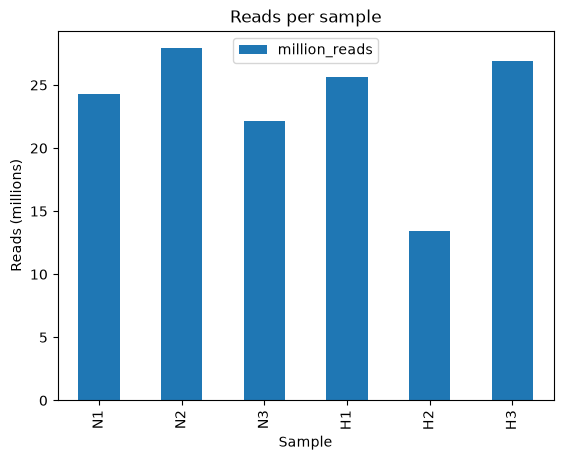

In [4]:
samples.plot(kind='bar', x='sample', y='million_reads',
             title='Reads per sample', xlabel='Sample', ylabel='Reads (millions)')

**4.** Sample `H2` has only about 13 million reads, half of the other samples, and only 71% of its reads map to the genome (the others: 94-95%). Something went wrong with this sample, for example degraded RNA, contamination or a problem during sequencing.

**5.**

In [5]:
samples.groupby('condition')['million_reads'].mean()

condition
hypoxia     21.973484
normoxia    24.791179
Name: million_reads, dtype: float64

The hypoxia mean is lower because of sample `H2`.

## Part 2 - The results

**6.**

In [6]:
results = pd.read_excel(file, sheet_name='DE_results')
results.shape

(198, 6)

There are **198 genes**.

In [7]:
results.info()

<class 'pandas.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gene            198 non-null    str    
 1   chromosome      198 non-null    str    
 2   baseMean        198 non-null    float64
 3   log2FoldChange  195 non-null    float64
 4   pvalue          195 non-null    float64
 5   padj            183 non-null    float64
dtypes: float64(4), str(2)
memory usage: 9.4 KB


`log2FoldChange`, `pvalue` and `padj` have missing values. `padj` has the most: DESeq2 does not calculate it for genes with very low expression.

**7.**

In [8]:
results[results['gene'] == 'ALB']

,gene,chromosome,baseMean,log2FoldChange,pvalue,padj
196,ALB,chr4,0.0,NaN,NaN,NaN


`baseMean` is `0`: albumin is not expressed at all in these cells, so there is nothing to compare between the conditions and DESeq2 cannot calculate a fold change or a p-value.

**8.**

In [9]:
results[results['gene'] == 'VEGFA']

,gene,chromosome,baseMean,log2FoldChange,pvalue,padj
176,VEGFA,chr6,423.37,3.952,4.421870e-22,3.853344e-21


In [10]:
2 ** 3.952

15.476421273822913

`VEGFA` is about **15 times higher** in hypoxia, as expected for a gene that helps make new blood vessels when oxygen is low.

**9.**

In [11]:
significant = results[results['padj'] < 0.05]
len(significant)

75

**10.**

In [12]:
up = results[(results['padj'] < 0.05) & (results['log2FoldChange'] > 1)]
down = results[(results['padj'] < 0.05) & (results['log2FoldChange'] < -1)]

print('Up:', len(up))
print('Down:', len(down))

Up: 35
Down: 18


35 + 18 = 53, but there are 75 significant genes. The other 22 genes are significant but change **less than 2 times**. With 3 replicates, even small changes can be statistically significant, but they are often not interesting biologically.

**11.**

In [13]:
up.sort_values('log2FoldChange', ascending=False).head(10)[['gene', 'log2FoldChange', 'padj']]

,gene,log2FoldChange,padj
158,CA9,6.840,5.856000e-43
133,PLOD2,5.456,3.219204e-07
103,LDHA,5.358,3.284741e-36
195,HILPDA,5.272,5.342517e-06
138,FAM162A,5.251,7.029446e-32
102,ZNF395,5.029,3.284741e-36
8,ANKRD37,5.020,2.821815e-26
151,HK2,4.961,3.742129e-32
172,ERO1A,4.614,6.741101e-23
166,MXI1,4.494,1.593134e-07


`CA9` is on top: it is one of the best known markers of hypoxia.

**12.**

<Axes: title={'center': 'Fold changes of all genes'}, xlabel='log2 fold change', ylabel='Frequency'>

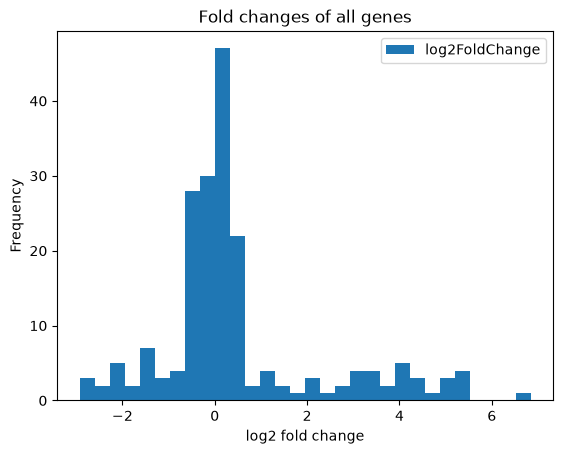

In [14]:
results.plot(kind='hist', y='log2FoldChange', bins=30,
             title='Fold changes of all genes', xlabel='log2 fold change')

Most genes are around `0`: they do not change. Only a few genes are far from 0, on both sides.

**13.**

In [15]:
up['chromosome'].value_counts()

chromosome
chr10    5
chr2     4
chr3     4
chr1     3
chr8     3
chr19    2
chr11    2
chr5     2
chr14    2
chr17    1
chr4     1
chr12    1
chr16    1
chr9     1
chrX     1
chr6     1
chr7     1
Name: count, dtype: int64

<Axes: title={'center': 'Up-regulated genes per chromosome'}, xlabel='Chromosome', ylabel='Number of genes'>

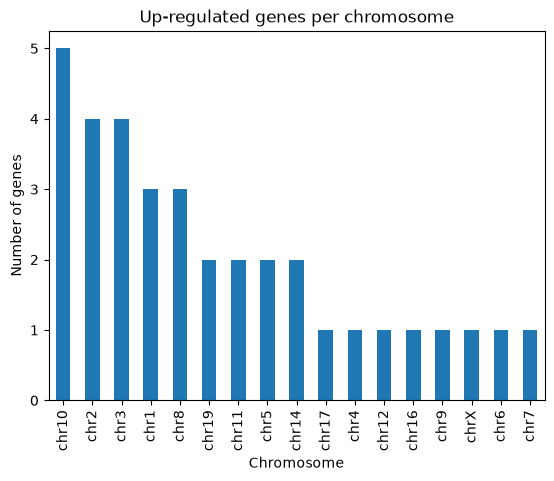

In [16]:
up['chromosome'].value_counts().plot(kind='bar', title='Up-regulated genes per chromosome',
                                     xlabel='Chromosome', ylabel='Number of genes')

The genes are spread over many chromosomes: genes that work together are often **not** next to each other in the genome.

**14.**

In [17]:
up.to_csv('hypoxia_up_genes.csv', index=False)

pd.read_csv('hypoxia_up_genes.csv')

,gene,chromosome,baseMean,log2FoldChange,pvalue,padj
0,SLC2A1,chr1,754.20,1.963,1.420797e-28,2.600058e-27
1,ALDOC,chr17,343.12,4.339,1.003842e-16,6.551513e-16
2,ANKRD37,chr4,254.61,5.020,1.850371e-27,2.821815e-26
3,P4HA1,chr10,5551.09,2.684,7.266199e-39,6.648573e-37
4,INSIG2,chr2,501.43,1.599,3.547921e-06,1.226756e-05
5,EGLN1,chr1,866.81,4.036,7.724884e-25,8.835336e-24
6,ENO1,chr1,2220.80,2.203,1.056672e-26,1.289140e-25
7,ANGPTL4,chr19,633.42,4.193,1.038218e-16,6.551513e-16
8,KDM4B,chr19,6856.21,3.313,8.945935e-27,1.169362e-25
9,DDIT4,chr10,494.43,3.682,2.694806e-20,2.241589e-19


## Part 3 - Challenges

**A.**

Text(0, 0.5, '-log10(padj)')

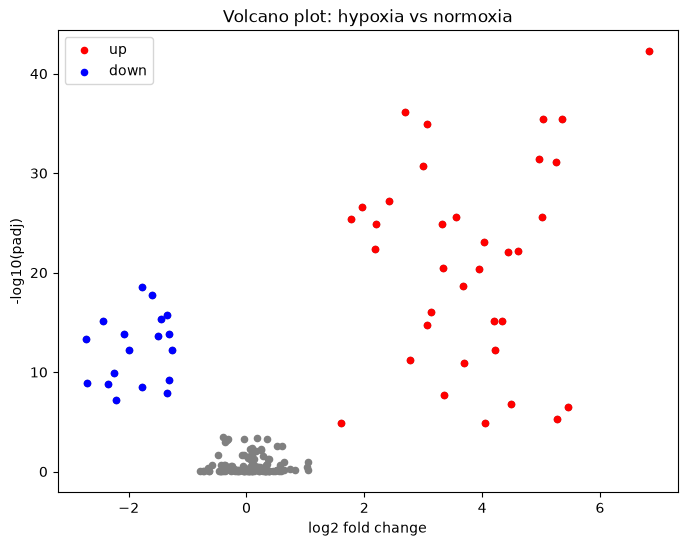

In [18]:
import numpy as np

results['minus_log10_padj'] = -np.log10(results['padj'])

# select again, so that up and down also have the new column
up = results[(results['padj'] < 0.05) & (results['log2FoldChange'] > 1)]
down = results[(results['padj'] < 0.05) & (results['log2FoldChange'] < -1)]

ax = results.plot(kind='scatter', x='log2FoldChange', y='minus_log10_padj', color='grey', figsize=(8, 6))
up.plot(kind='scatter', x='log2FoldChange', y='minus_log10_padj', color='red', ax=ax, label='up')
down.plot(kind='scatter', x='log2FoldChange', y='minus_log10_padj', color='blue', ax=ax, label='down')

# set the title and labels at the end: each plot call above resets the axis labels
ax.set_title('Volcano plot: hypoxia vs normoxia')
ax.set_xlabel('log2 fold change')
ax.set_ylabel('-log10(padj)')

Genes with a missing `padj` are not drawn: pandas skips missing values when plotting.

**B.**

In [19]:
def find_genes(results, direction='up', padj_cutoff=0.05, lfc_cutoff=1):
    """
    Find the up- or down-regulated genes in a DESeq2 result table.

    Parameters:
        results: dataframe with the columns padj and log2FoldChange
        direction: 'up' or 'down'
        padj_cutoff: maximum adjusted p-value
        lfc_cutoff: minimum change, as a positive log2 fold change

    Returns:
        A dataframe with the selected genes.
    """
    significant = results[results['padj'] < padj_cutoff]
    if direction == 'up':
        return significant[significant['log2FoldChange'] > lfc_cutoff]
    elif direction == 'down':
        return significant[significant['log2FoldChange'] < -lfc_cutoff]
    else:
        raise ValueError("direction must be 'up' or 'down', not " + repr(direction))

In [20]:
len(find_genes(results, lfc_cutoff=2))

32

In [21]:
len(find_genes(results, direction='down'))

18

In [22]:
find_genes(results, direction='sideways')

ValueError: direction must be 'up' or 'down', not 'sideways'

**C.**

<Axes: title={'center': 'MA plot'}, xlabel='Mean expression (log scale)', ylabel='log2 fold change'>

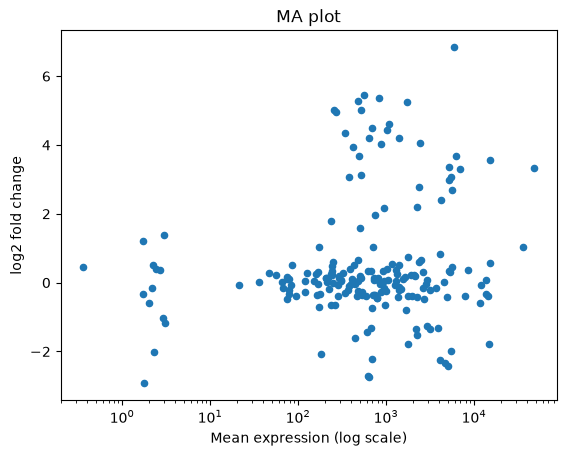

In [23]:
results.plot(kind='scatter', x='baseMean', y='log2FoldChange', logx=True,
             title='MA plot', xlabel='Mean expression (log scale)', ylabel='log2 fold change')

With `logx=True` the genes spread out over the whole x axis. You can see that genes with low expression (on the left) have more variable fold changes: with few reads, the estimates are less precise.

**D.** A sample like `H2` is called an **outlier**. Bioinformaticians usually check it with quality control plots (for example a PCA plot of all samples). If it really is bad, they **remove it** and run the analysis again with the remaining samples, and they write in their report why it was removed.